## 1. Análisis Exploratorio de Datos (EDA) e Ingesta

Total de muestras capturadas: 2713
Ciclos completos detectados: 6
Voltaje máximo registrado: 3.368 V


,tiempo_us,fase,adc_valor,tiempo_s,voltaje_v,ciclo
0,4,CARGA,3,0.000004,0.014663,1
1,2004,CARGA,30,0.002004,0.146628,1
2,4004,CARGA,56,0.004004,0.273705,1
3,6008,CARGA,81,0.006008,0.395894,1
4,8008,CARGA,105,0.008008,0.513196,1


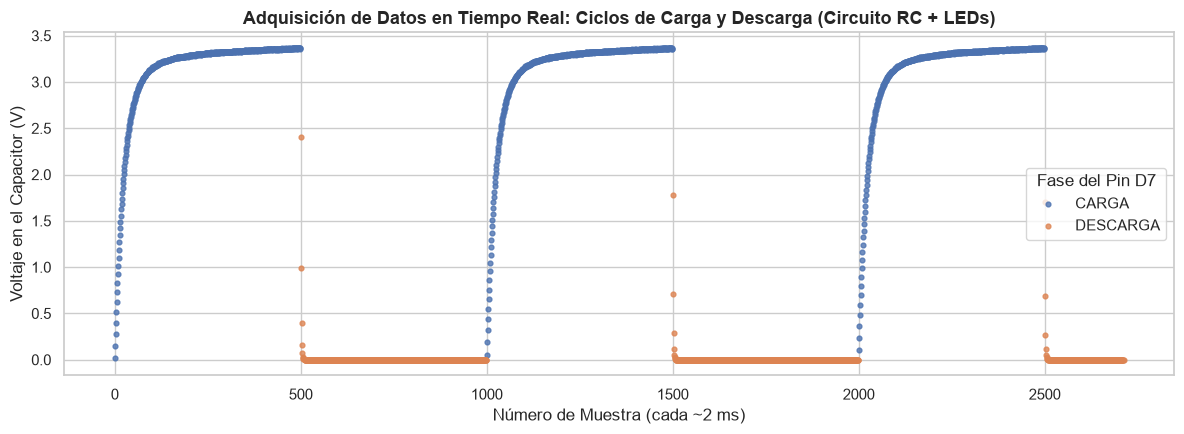

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, root_mean_squared_error

sns.set_theme(style="whitegrid", context="notebook")

# Leemos el archivo limpio que creó etl_capture.py
df = pd.read_csv("../data/processed/rc_clean_data.csv")

print(f"Total de muestras capturadas: {len(df)}")
print(f"Ciclos completos detectados: {df['ciclo'].nunique()}")
print(f"Voltaje máximo registrado: {df['voltaje_v'].max():.3f} V")
display(df.head())

# Gráfica 1: Todos los ciclos capturados
plt.figure(figsize=(12, 4.5))
for fase, grupo in df.groupby("fase"):
    plt.scatter(grupo.index, grupo["voltaje_v"], label=fase, s=12, alpha=0.8)

plt.title("Adquisición de Datos en Tiempo Real: Ciclos de Carga y Descarga (Circuito RC + LEDs)", fontsize=13, fontweight="bold")
plt.xlabel("Número de Muestra (cada ~2 ms)")
plt.ylabel("Voltaje en el Capacitor (V)")
plt.legend(title="Fase del Pin D7")
plt.tight_layout()
plt.show()

## 2. Modelado Físico y Regresión No Lineal (`SciPy`)
Ajuste por mínimos cuadrados no lineales sobre un ciclo aislado para estimar experimentalmente la constante de tiempo ($\tau = R \cdot C$) de carga y descarga mediante las ecuaciones diferenciales del circuito:
* **Carga:** $V(t) = V_{\max}(1 - e^{-t/\tau}) + V_{\text{offset}}$
* **Descarga:** $V(t) = V_0 e^{-t/\tau} + V_{\text{offset}}$


In [9]:
# Identificamos cada bloque continuo (cada ciclo de CARGA o DESCARGA)
df["segmento"] = (df["fase"] != df["fase"].shift()).cumsum()

# Extraemos los identificadores de cada bloque
bloques_carga = df[df["fase"] == "CARGA"]["segmento"].unique()
bloques_descarga = df[df["fase"] == "DESCARGA"]["segmento"].unique()

# Tomamos el segundo bloque (índice 1) usando .item() para garantizar un número entero único
id_carga = int(bloques_carga.item(1)) if len(bloques_carga) > 1 else int(bloques_carga.item(0))
id_descarga = int(bloques_descarga.item(1)) if len(bloques_descarga) > 1 else int(bloques_descarga.item(0))

df_carga = df[df["segmento"] == id_carga].copy()
df_descarga = df[df["segmento"] == id_descarga].copy()

# Reiniciamos el tiempo a t = 0 s al inicio de cada fase
df_carga["t_norm"] = df_carga["tiempo_s"] - df_carga["tiempo_s"].min()
df_descarga["t_norm"] = df_descarga["tiempo_s"] - df_descarga["tiempo_s"].min()

# Fórmulas físicas exponenciales
def modelo_carga(t, v_max, tau, v_offset):
    return v_max * (1 - np.exp(-t / tau)) + v_offset

def modelo_descarga(t, v0, tau, v_offset):
    return v0 * np.exp(-t / tau) + v_offset

# Ajuste matemático no lineal
popt_carga, _ = curve_fit(modelo_carga, df_carga["t_norm"], df_carga["voltaje_v"], p0=[2.0, 0.05, 0.0], maxfev=5000)
v_max_exp, tau_carga_exp, offset_carga = popt_carga

popt_descarga, _ = curve_fit(modelo_descarga, df_descarga["t_norm"], df_descarga["voltaje_v"], p0=[2.0, 0.05, 0.0], maxfev=5000)
v0_exp, tau_descarga_exp, offset_descarga = popt_descarga

# Valor teórico esperado (R = 443.4 Ω, C = 100 µF)
R_total = 443.4
C_nominal = 100e-6
tau_teorico = R_total * C_nominal

print("=== RESULTADOS DEL MODELADO FÍSICO ===")
print(f"Muestras analizadas -> Carga: {len(df_carga)} | Descarga: {len(df_descarga)}")
print(f"Constante de tiempo teórica (R·C):     {tau_teorico:.5f} s ({tau_teorico*1000:.2f} ms)")
print(f"Constante de tiempo CARGA (Exp):       {tau_carga_exp:.5f} s ({tau_carga_exp*1000:.2f} ms)")
print(f"Constante de tiempo DESCARGA (Exp):    {tau_descarga_exp:.5f} s ({tau_descarga_exp*1000:.2f} ms)")
print(f"Voltaje de estabilización (LED):       {v_max_exp + offset_carga:.3f} V")


=== RESULTADOS DEL MODELADO FÍSICO ===
Muestras analizadas -> Carga: 500 | Descarga: 500
Constante de tiempo teórica (R·C):     0.04434 s (44.34 ms)
Constante de tiempo CARGA (Exp):       0.05816 s (58.16 ms)
Constante de tiempo DESCARGA (Exp):    0.00219 s (2.19 ms)
Voltaje de estabilización (LED):       3.314 V


## 3. Evaluación Estadística y Visualización Comparativa
Cálculo de métricas de bondad de ajuste ($R^2$ y error cuadrático medio $\text{RMSE}$) y exportación de curvas comparativas entre los datos experimentales y el modelo teórico.


Métricas Carga    -> R²: 0.9940 | RMSE: 0.0393 V
Métricas Descarga -> R²: 1.0000 | RMSE: 0.0005 V


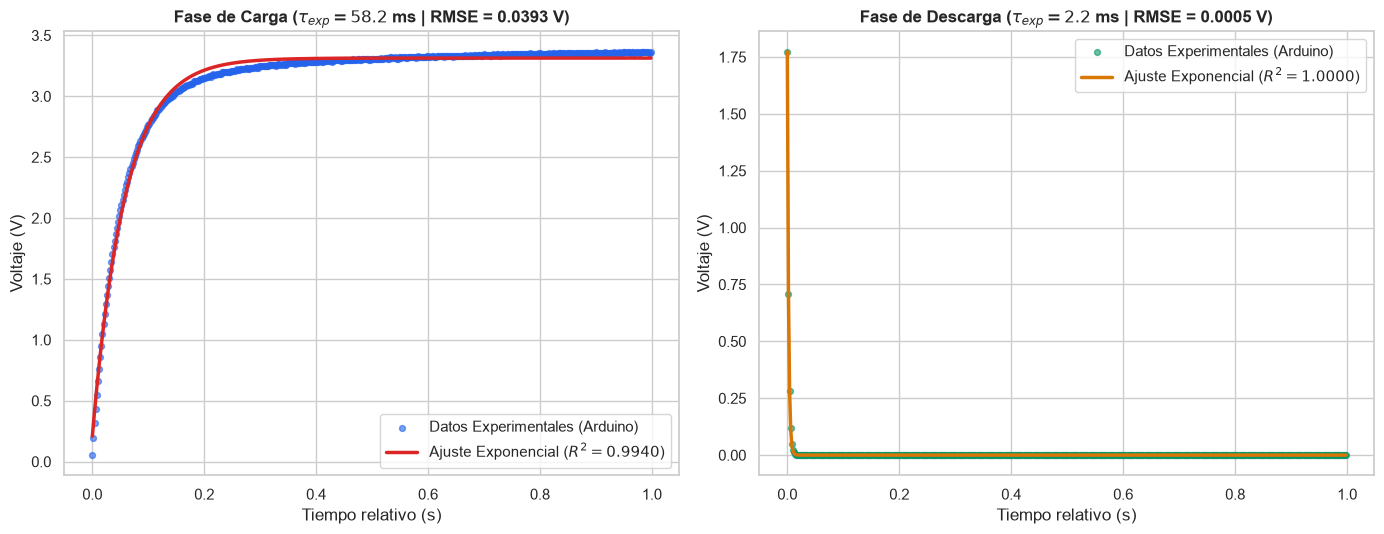

In [10]:
v_pred_carga = modelo_carga(df_carga["t_norm"], *popt_carga)
v_pred_descarga = modelo_descarga(df_descarga["t_norm"], *popt_descarga)

r2_carga = r2_score(df_carga["voltaje_v"], v_pred_carga)
rmse_carga = root_mean_squared_error(df_carga["voltaje_v"], v_pred_carga)

r2_descarga = r2_score(df_descarga["voltaje_v"], v_pred_descarga)
rmse_descarga = root_mean_squared_error(df_descarga["voltaje_v"], v_pred_descarga)

print(f"Métricas Carga    -> R²: {r2_carga:.4f} | RMSE: {rmse_carga:.4f} V")
print(f"Métricas Descarga -> R²: {r2_descarga:.4f} | RMSE: {rmse_descarga:.4f} V")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel Izquierdo: Fase de Carga
axes[0].scatter(df_carga["t_norm"], df_carga["voltaje_v"], color="#2563EB", s=18, alpha=0.6, label="Datos Experimentales (Arduino)")
axes[0].plot(df_carga["t_norm"], v_pred_carga, color="#DC2626", linewidth=2.5, label=f"Ajuste Exponencial ($R^2={r2_carga:.4f}$)")
axes[0].set_title(f"Fase de Carga ($\\tau_{{exp}} = {tau_carga_exp*1000:.1f}$ ms | RMSE = {rmse_carga:.4f} V)", fontweight="bold")
axes[0].set_xlabel("Tiempo relativo (s)")
axes[0].set_ylabel("Voltaje (V)")
axes[0].legend()

# Panel Derecho: Fase de Descarga
axes[1].scatter(df_descarga["t_norm"], df_descarga["voltaje_v"], color="#059669", s=18, alpha=0.6, label="Datos Experimentales (Arduino)")
axes[1].plot(df_descarga["t_norm"], v_pred_descarga, color="#D97706", linewidth=2.5, label=f"Ajuste Exponencial ($R^2={r2_descarga:.4f}$)")
axes[1].set_title(f"Fase de Descarga ($\\tau_{{exp}} = {tau_descarga_exp*1000:.1f}$ ms | RMSE = {rmse_descarga:.4f} V)", fontweight="bold")
axes[1].set_xlabel("Tiempo relativo (s)")
axes[1].set_ylabel("Voltaje (V)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../curvas_rc_resultados.png", dpi=300)
plt.show()


## 4. Diagnóstico Estadístico mediante Análisis de Residuos
Evaluación de la diferencia entre el voltaje medido y la predicción teórica ($V_{\text{real}} - V_{\text{modelo}}$) para identificar comportamientos no lineales asociados a la barrera de potencial de los diodos LED.


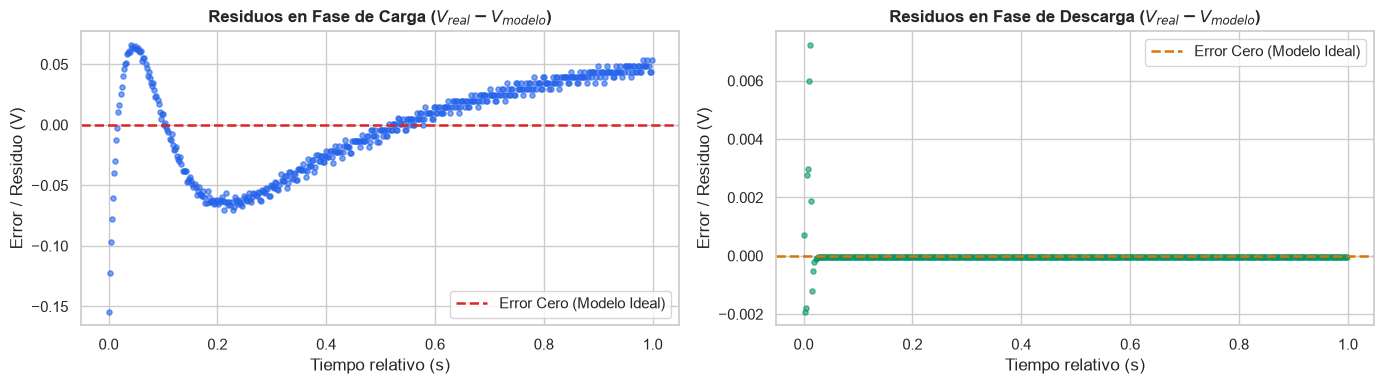

Desviación estándar del ruido en Carga:    0.0393 V
Desviación estándar del ruido en Descarga: 0.0005 V


In [ ]:
# Validación Estadística del Modelo Físico
residuos_carga = df_carga["voltaje_v"] - v_pred_carga
residuos_descarga = df_descarga["voltaje_v"] - v_pred_descarga

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Residuos en Carga
axes[0].scatter(df_carga["t_norm"], residuos_carga, color="#2563EB", s=14, alpha=0.6)
axes[0].axhline(0, color="#DC2626", linestyle="--", linewidth=1.8, label="Error Cero (Modelo Ideal)")
axes[0].set_title("Residuos en Fase de Carga ($V_{real} - V_{modelo}$)", fontweight="bold")
axes[0].set_xlabel("Tiempo relativo (s)")
axes[0].set_ylabel("Error / Residuo (V)")
axes[0].legend()

# Residuos en Descarga
axes[1].scatter(df_descarga["t_norm"], residuos_descarga, color="#059669", s=14, alpha=0.6)
axes[1].axhline(0, color="#D97706", linestyle="--", linewidth=1.8, label="Error Cero (Modelo Ideal)")
axes[1].set_title("Residuos en Fase de Descarga ($V_{real} - V_{modelo}$)", fontweight="bold")
axes[1].set_xlabel("Tiempo relativo (s)")
axes[1].set_ylabel("Error / Residuo (V)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../residuos_rc_resultados.png", dpi=300)
plt.show()

print(f"Desviación estándar del ruido en Carga:    {residuos_carga.std():.4f} V")
print(f"Desviación estándar del ruido en Descarga: {residuos_descarga.std():.4f} V")
